In [4]:
%pip install duckdb

Note: you may need to restart the kernel to use updated packages.


In [5]:
import duckdb

df = duckdb.query("""
    SELECT *
    FROM 'yellow_tripdata_2025-01.parquet'
    LIMIT 5
""").df()

display(df)

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,1,2025-01-01 00:18:38,2025-01-01 00:26:59,1,1.60,1,N,229,237,1,10.0,3.5,0.5,3.00,0.0,1.0,18.00,2.5,0.0,0.0
1,1,2025-01-01 00:32:40,2025-01-01 00:35:13,1,0.50,1,N,236,237,1,5.1,3.5,0.5,2.02,0.0,1.0,12.12,2.5,0.0,0.0
2,1,2025-01-01 00:44:04,2025-01-01 00:46:01,1,0.60,1,N,141,141,1,5.1,3.5,0.5,2.00,0.0,1.0,12.10,2.5,0.0,0.0
3,2,2025-01-01 00:14:27,2025-01-01 00:20:01,3,0.52,1,N,244,244,2,7.2,1.0,0.5,0.00,0.0,1.0,9.70,0.0,0.0,0.0
4,2,2025-01-01 00:21:34,2025-01-01 00:25:06,3,0.66,1,N,244,116,2,5.8,1.0,0.5,0.00,0.0,1.0,8.30,0.0,0.0,0.0


In [6]:
# Display column names and data types

columns = duckdb.sql("""
    DESCRIBE SELECT *
    FROM 'yellow_tripdata_2025-01.parquet'
""").df()

display(columns)

,column_name,column_type,null,key,default,extra
0,VendorID,INTEGER,YES,None,None,None
1,tpep_pickup_datetime,TIMESTAMP,YES,None,None,None
2,tpep_dropoff_datetime,TIMESTAMP,YES,None,None,None
3,passenger_count,BIGINT,YES,None,None,None
4,trip_distance,DOUBLE,YES,None,None,None
5,RatecodeID,BIGINT,YES,None,None,None
6,store_and_fwd_flag,VARCHAR,YES,None,None,None
7,PULocationID,INTEGER,YES,None,None,None
8,DOLocationID,INTEGER,YES,None,None,None
9,payment_type,BIGINT,YES,None,None,None


In [7]:
# Dataset overview

overview = duckdb.sql("""
    SELECT
        COUNT(*) AS total_records,
        MIN(tpep_pickup_datetime) AS first_pickup,
        MAX(tpep_pickup_datetime) AS last_pickup,
        AVG(trip_distance) AS avg_trip_distance,
        AVG(fare_amount) AS avg_fare
    FROM 'yellow_tripdata_2025-01.parquet'
""").df()

display(overview)

,total_records,first_pickup,last_pickup,avg_trip_distance,avg_fare
0,3475226,2024-12-31 20:47:55,2025-02-01 00:00:44,5.855126,17.081803


In [8]:
# Check missing and potentially invalid values

quality_check = duckdb.sql("""
    SELECT
        COUNT(*) AS total_records,

        SUM(CASE
            WHEN tpep_pickup_datetime IS NULL
            THEN 1 ELSE 0
        END) AS missing_pickup_time,

        SUM(CASE
            WHEN PULocationID IS NULL
            THEN 1 ELSE 0
        END) AS missing_pickup_location,

        SUM(CASE
            WHEN trip_distance <= 0
            THEN 1 ELSE 0
        END) AS non_positive_distance,

        SUM(CASE
            WHEN fare_amount <= 0
            THEN 1 ELSE 0
        END) AS non_positive_fare,

        SUM(CASE
            WHEN tpep_dropoff_datetime <= tpep_pickup_datetime
            THEN 1 ELSE 0
        END) AS invalid_trip_duration

    FROM 'yellow_tripdata_2025-01.parquet'
""").df()

display(quality_check)

,total_records,missing_pickup_time,missing_pickup_location,non_positive_distance,non_positive_fare,invalid_trip_duration
0,3475226,0.0,0.0,90893.0,145516.0,2051.0


In [9]:

# Create a cleaned analytical view

duckdb.sql("""
CREATE OR REPLACE VIEW clean_taxi AS
SELECT *
FROM 'yellow_tripdata_2025-01.parquet'
WHERE
    tpep_pickup_datetime >= '2025-01-01'
    AND tpep_pickup_datetime < '2025-02-01'
    AND tpep_dropoff_datetime > tpep_pickup_datetime
    AND trip_distance > 0
    AND fare_amount > 0
    AND PULocationID > 0
    AND DOLocationID > 0
""")

# Compare original and cleaned records
duckdb.sql("""
SELECT
    (SELECT COUNT(*)
     FROM 'yellow_tripdata_2025-01.parquet')
        AS original_records,

    (SELECT COUNT(*)
     FROM clean_taxi)
        AS cleaned_records
""").show()


┌──────────────────┬─────────────────┐
│ original_records │ cleaned_records │
│      int64       │      int64      │
├──────────────────┼─────────────────┤
│          3475226 │         3252492 │
└──────────────────┴─────────────────┘



,trip_date,total_trips
0,2025-01-01,81017
1,2025-01-02,80650
2,2025-01-03,87051
3,2025-01-04,93775
4,2025-01-05,76113
5,2025-01-06,76790
6,2025-01-07,95752
7,2025-01-08,107156
8,2025-01-09,111960
9,2025-01-10,104847


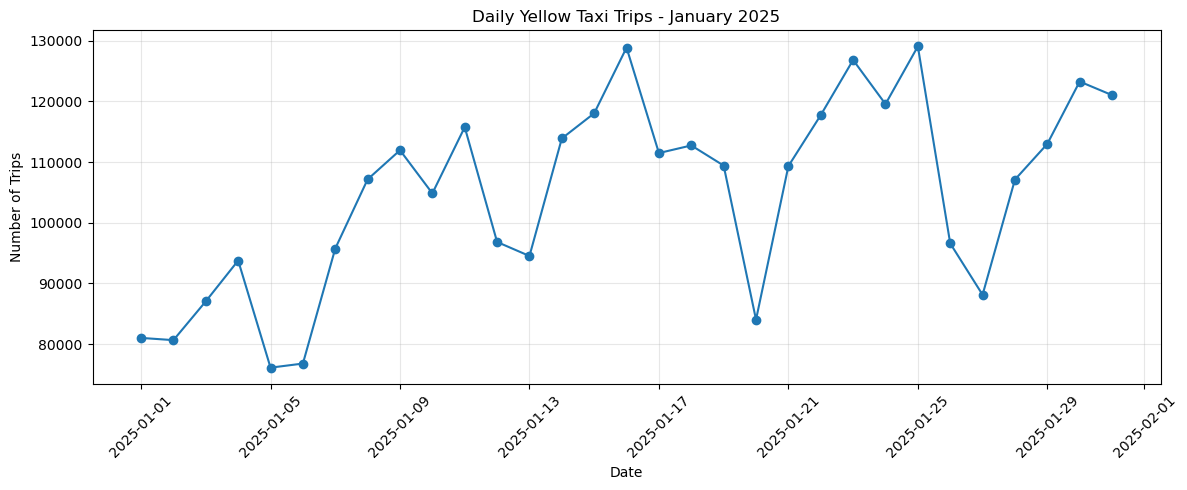

In [10]:

import matplotlib.pyplot as plt

# Calculate daily taxi trips using DuckDB
daily_trips = duckdb.sql("""
    SELECT
        CAST(tpep_pickup_datetime AS DATE) AS trip_date,
        COUNT(*) AS total_trips
    FROM clean_taxi
    GROUP BY trip_date
    ORDER BY trip_date
""").df()

display(daily_trips)

# Plot daily demand
plt.figure(figsize=(12, 5))

plt.plot(
    daily_trips["trip_date"],
    daily_trips["total_trips"],
    marker="o"
)

plt.title("Daily Yellow Taxi Trips - January 2025")
plt.xlabel("Date")
plt.ylabel("Number of Trips")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,number_of_days,average_daily_trips,median_daily_trips,std_daily_trips
day_type,,,,
Weekday,23,105311.09,109340.0,16024.25
Weekend,8,103792.12,103130.5,16306.19


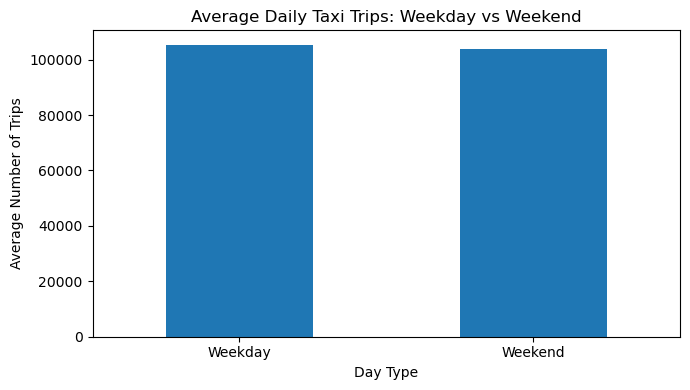

In [11]:

import pandas as pd
import matplotlib.pyplot as plt

# Use daily trip counts from Cell 7
daily_trips["trip_date"] = pd.to_datetime(daily_trips["trip_date"])

# Classify each date
daily_trips["day_type"] = daily_trips["trip_date"].dt.dayofweek.apply(
    lambda x: "Weekend" if x >= 5 else "Weekday"
)

# Calculate descriptive statistics
demand_comparison = (
    daily_trips.groupby("day_type")["total_trips"]
    .agg(
        number_of_days="count",
        average_daily_trips="mean",
        median_daily_trips="median",
        std_daily_trips="std"
    )
    .round(2)
)

display(demand_comparison)

# Visualize average daily demand
demand_comparison["average_daily_trips"].plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Average Daily Taxi Trips: Weekday vs Weekend")
plt.xlabel("Day Type")
plt.ylabel("Average Number of Trips")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,pickup_hour,total_trips
0,0,86529
1,1,59508
2,2,40206
3,3,25557
4,4,17932
5,5,20518
6,6,46608
7,7,96740
8,8,133770
9,9,137172


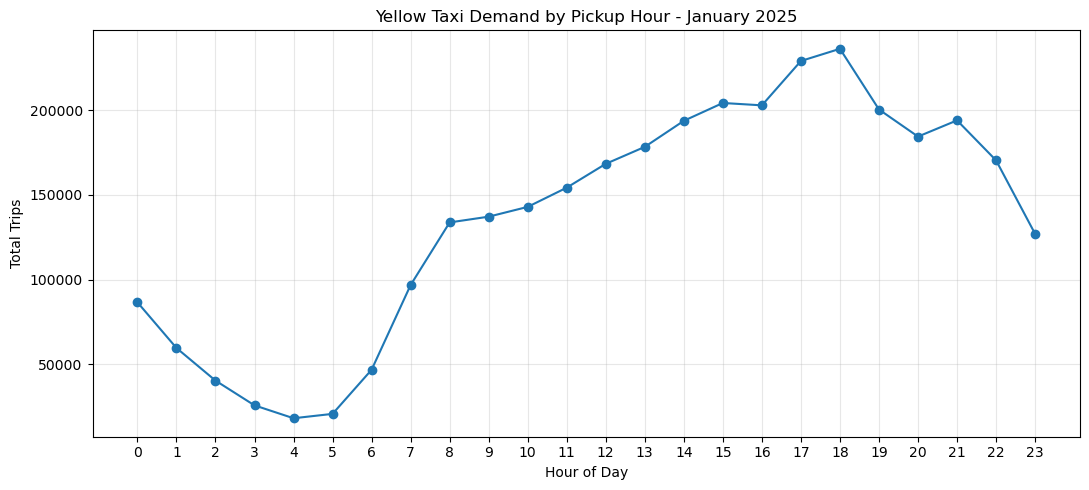

In [12]:

# Calculate trips by pickup hour

hourly_demand = duckdb.sql("""
    SELECT
        EXTRACT(HOUR FROM tpep_pickup_datetime) AS pickup_hour,
        COUNT(*) AS total_trips
    FROM clean_taxi
    GROUP BY pickup_hour
    ORDER BY pickup_hour
""").df()

display(hourly_demand)

# Plot hourly demand
plt.figure(figsize=(11, 5))

plt.plot(
    hourly_demand["pickup_hour"],
    hourly_demand["total_trips"],
    marker="o"
)

plt.title("Yellow Taxi Demand by Pickup Hour - January 2025")
plt.xlabel("Hour of Day")
plt.ylabel("Total Trips")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


,pickup_hour,day_type,total_trips,average_trips
0,0,Weekday,39848,1732.521739
1,0,Weekend,46681,5835.125000
2,1,Weekday,22942,997.478261
3,1,Weekend,36566,4570.750000
4,2,Weekday,14688,638.608696
5,2,Weekend,25518,3189.750000
6,3,Weekday,9888,429.913043
7,3,Weekend,15669,1958.625000
8,4,Weekday,9593,417.086957
9,4,Weekend,8339,1042.375000


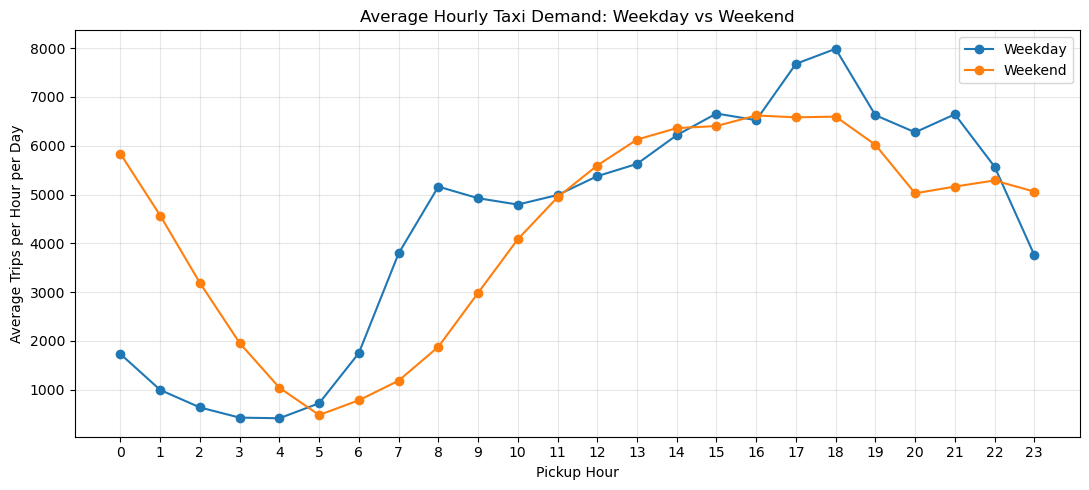

In [13]:

# Hourly demand by weekday and weekend

hourly_comparison = duckdb.sql("""
    SELECT
        EXTRACT(HOUR FROM tpep_pickup_datetime) AS pickup_hour,
        CASE
            WHEN EXTRACT(ISODOW FROM tpep_pickup_datetime)
                 IN (6, 7)
            THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,
        COUNT(*) AS total_trips
    FROM clean_taxi
    GROUP BY pickup_hour, day_type
    ORDER BY pickup_hour, day_type
""").df()

# Average trips per hour per day
hourly_comparison["average_trips"] = (
    hourly_comparison["total_trips"] /
    hourly_comparison["day_type"].map({
        "Weekday": 23,
        "Weekend": 8
    })
)

display(hourly_comparison)

# Plot
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

for day_type in ["Weekday", "Weekend"]:
    subset = hourly_comparison[
        hourly_comparison["day_type"] == day_type
    ]

    plt.plot(
        subset["pickup_hour"],
        subset["average_trips"],
        marker="o",
        label=day_type
    )

plt.title("Average Hourly Taxi Demand: Weekday vs Weekend")
plt.xlabel("Pickup Hour")
plt.ylabel("Average Trips per Hour per Day")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# Cell 11 - Daily summary for Power BI

daily_summary = duckdb.sql("""
    SELECT
        CAST(tpep_pickup_datetime AS DATE) AS trip_date,
        COUNT(*) AS total_trips,
        ROUND(SUM(total_amount), 2) AS total_passenger_charges,
        ROUND(AVG(fare_amount), 2) AS avg_fare,
        ROUND(AVG(trip_distance), 2) AS avg_distance_miles,
        ROUND(AVG(
            DATE_DIFF(
                'minute',
                tpep_pickup_datetime,
                tpep_dropoff_datetime
            )
        ), 2) AS avg_duration_minutes
    FROM clean_taxi
    GROUP BY trip_date
    ORDER BY trip_date
""").df()

display(daily_summary)

# Save the summary for Power BI
daily_summary.to_csv(
    "daily_summary.csv",
    index=False
)

print("Daily summary exported successfully!")


,trip_date,total_trips,total_passenger_charges,avg_fare,avg_distance_miles,avg_duration_minutes
0,2025-01-01,81017,2315302.40,20.22,4.83,15.75
1,2025-01-02,80650,2376636.91,20.26,3.74,16.93
2,2025-01-03,87051,2439553.95,19.07,6.19,16.09
3,2025-01-04,93775,2502964.72,18.54,3.28,15.14
4,2025-01-05,76113,2229703.79,20.01,3.88,14.84
5,2025-01-06,76790,2211440.63,19.14,3.57,15.25
6,2025-01-07,95752,2576920.78,17.62,3.51,14.93
7,2025-01-08,107156,2818990.34,17.20,2.97,14.78
8,2025-01-09,111960,3006182.29,17.63,5.43,15.47
9,2025-01-10,104847,2852685.13,17.93,5.19,15.17


Daily summary exported successfully!


In [15]:

# Cell 12 - Geographic summary for Power BI

geographic_summary = duckdb.sql("""
    SELECT
        PULocationID AS pickup_zone_id,
        DOLocationID AS dropoff_zone_id,
        COUNT(*) AS total_trips,
        ROUND(SUM(total_amount), 2) AS total_passenger_charges,
        ROUND(AVG(fare_amount), 2) AS avg_fare,
        ROUND(AVG(trip_distance), 2) AS avg_distance_miles
    FROM clean_taxi
    GROUP BY
        PULocationID,
        DOLocationID
    ORDER BY total_trips DESC
""").df()

display(geographic_summary.head(10))

# Export to CSV
geographic_summary.to_csv(
    "geographic_summary.csv",
    index=False
)

print("Geographic summary exported successfully!")
print("Total route pairs:", len(geographic_summary))


,pickup_zone_id,dropoff_zone_id,total_trips,total_passenger_charges,avg_fare,avg_distance_miles
0,237,236,24373,380127.02,8.66,1.04
1,236,237,21328,336642.39,9.03,1.03
2,236,236,17116,226243.15,6.79,0.63
3,237,237,16245,224441.50,7.14,0.65
4,161,237,11154,196803.81,9.66,1.05
5,237,161,9894,175079.55,10.19,1.04
6,161,236,9575,213161.94,13.56,1.92
7,239,238,9327,128455.39,7.17,0.84
8,142,239,8937,133776.04,7.95,0.98
9,239,142,8571,123504.32,7.68,11.02


Geographic summary exported successfully!
Total route pairs: 31593


In [16]:

# Cell 13 - Hourly demand summary for Power BI

hourly_summary = duckdb.sql("""
    SELECT
        CAST(tpep_pickup_datetime AS DATE) AS trip_date,

        EXTRACT(HOUR FROM tpep_pickup_datetime)
            AS pickup_hour,

        DAYNAME(tpep_pickup_datetime)
            AS day_name,

        CASE
            WHEN EXTRACT(ISODOW FROM tpep_pickup_datetime)
                 IN (6, 7)
            THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,

        COUNT(*) AS total_trips,

        ROUND(AVG(trip_distance), 2)
            AS avg_distance_miles,

        ROUND(AVG(fare_amount), 2)
            AS avg_fare

    FROM clean_taxi

    GROUP BY
        trip_date,
        pickup_hour,
        day_name,
        day_type

    ORDER BY trip_date, pickup_hour
""").df()

display(hourly_summary.head(10))

# Export for Power BI
hourly_summary.to_csv(
    "hourly_summary.csv",
    index=False
)

print("Hourly summary exported successfully!")
print("Total rows:", len(hourly_summary))


,trip_date,pickup_hour,day_name,day_type,total_trips,avg_distance_miles,avg_fare
0,2025-01-01,0,Wednesday,Weekday,6717,3.23,18.43
1,2025-01-01,1,Wednesday,Weekday,7591,3.21,19.23
2,2025-01-01,2,Wednesday,Weekday,6204,3.33,18.50
3,2025-01-01,3,Wednesday,Weekday,3891,3.30,16.81
4,2025-01-01,4,Wednesday,Weekday,2413,3.87,17.83
5,2025-01-01,5,Wednesday,Weekday,1099,4.95,21.89
6,2025-01-01,6,Wednesday,Weekday,975,6.28,26.24
7,2025-01-01,7,Wednesday,Weekday,923,6.10,26.17
8,2025-01-01,8,Wednesday,Weekday,988,5.60,24.56
9,2025-01-01,9,Wednesday,Weekday,1375,4.67,21.25


Hourly summary exported successfully!
Total rows: 744


In [17]:

# Cell 14 - Add readable taxi zone names

zone_lookup = duckdb.sql("""
    SELECT
        LocationID,
        Borough,
        Zone
    FROM 'taxi_zone_lookup.csv'
""").df()

display(zone_lookup.head())

geographic_named = duckdb.sql("""
    SELECT
        g.*,
        p.Borough AS pickup_borough,
        p.Zone AS pickup_zone,
        d.Borough AS dropoff_borough,
        d.Zone AS dropoff_zone
    FROM geographic_summary g
    LEFT JOIN zone_lookup p
        ON g.pickup_zone_id = p.LocationID
    LEFT JOIN zone_lookup d
        ON g.dropoff_zone_id = d.LocationID
    ORDER BY g.total_trips DESC
""").df()

display(geographic_named.head(10))

# Replace the earlier geographic CSV
geographic_named.to_csv(
    "geographic_summary.csv",
    index=False
)

print("Geographic summary updated successfully!")
print("Total zone pairs:", len(geographic_named))


,LocationID,Borough,Zone
0,1,EWR,Newark Airport
1,2,Queens,Jamaica Bay
2,3,Bronx,Allerton/Pelham Gardens
3,4,Manhattan,Alphabet City
4,5,Staten Island,Arden Heights


,pickup_zone_id,dropoff_zone_id,total_trips,total_passenger_charges,avg_fare,avg_distance_miles,pickup_borough,pickup_zone,dropoff_borough,dropoff_zone
0,237,236,24373,380127.02,8.66,1.04,Manhattan,Upper East Side South,Manhattan,Upper East Side North
1,236,237,21328,336642.39,9.03,1.03,Manhattan,Upper East Side North,Manhattan,Upper East Side South
2,236,236,17116,226243.15,6.79,0.63,Manhattan,Upper East Side North,Manhattan,Upper East Side North
3,237,237,16245,224441.50,7.14,0.65,Manhattan,Upper East Side South,Manhattan,Upper East Side South
4,161,237,11154,196803.81,9.66,1.05,Manhattan,Midtown Center,Manhattan,Upper East Side South
5,237,161,9894,175079.55,10.19,1.04,Manhattan,Upper East Side South,Manhattan,Midtown Center
6,161,236,9575,213161.94,13.56,1.92,Manhattan,Midtown Center,Manhattan,Upper East Side North
7,239,238,9327,128455.39,7.17,0.84,Manhattan,Upper West Side South,Manhattan,Upper West Side North
8,142,239,8937,133776.04,7.95,0.98,Manhattan,Lincoln Square East,Manhattan,Upper West Side South
9,239,142,8571,123504.32,7.68,11.02,Manhattan,Upper West Side South,Manhattan,Lincoln Square East


Geographic summary updated successfully!
Total zone pairs: 31593


In [18]:

# Export all 3 Power BI datasets as CSV

from pathlib import Path

datasets = {
    "daily_summary.csv": daily_summary,
    "geographic_summary.csv": geographic_named,
    "hourly_summary.csv": hourly_summary
}

for filename, df in datasets.items():
    df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"Created: {Path(filename).resolve()}")

print("\nAll 3 CSV files exported successfully!")


Created: C:\Users\Lenovo\daily_summary.csv
Created: C:\Users\Lenovo\geographic_summary.csv
Created: C:\Users\Lenovo\hourly_summary.csv

All 3 CSV files exported successfully!


In [20]:

# Export all 3 datasets as Excel workbooks

%pip install openpyxl

daily_summary.to_excel(
    "daily_summary.xlsx",
    index=False,
    engine="openpyxl"
)

geographic_named.to_excel(
    "geographic_summary.xlsx",
    index=False,
    engine="openpyxl"
)

hourly_summary.to_excel(
    "hourly_summary.xlsx",
    index=False,
    engine="openpyxl"
)

print("All 3 Excel files created successfully!")



All 3 Excel files created successfully!


In [1]:
%pip install geopandas


   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
   ---------------------------------------- 0.0/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
    --------------------------------------- 0.3/12.6 MB ? eta -:--:--
   - -------------------------------------- 0.5/12.6 MB 322.4 kB/s eta 0:00:38
   - -----

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow-decision-forests 1.8.1 requires wurlitzer, which is not installed.
contourpy 1.2.0 requires numpy<2.0,>=1.20, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.
scipy 1.13.1 requires numpy<2.3,>=1.22.4, but you have numpy 2.5.4 which is incompatible.
streamlit 1.52.2 requires protobuf<7,>=3.20, but you have protobuf 7.35.1 which is incompatible.
tensorflow-decision-forests 1.8.1 requires tensorflow~=2.15.0, but you have tensorflow 2.21.0 which is incompatible.


In [1]:
import geopandas as gpd

print("GeoPandas version:", gpd.__version__)

GeoPandas version: 1.2.0


In [4]:
import geopandas as gpd

zones = gpd.read_file(
    r"E:\Shreyas Kamat files\PROJECTS\PYTHON\P-6\taxi_zones\taxi_zones.shp"
)

# Calculate zone-center coordinates
zones = zones.to_crs(epsg=2263)
centers = zones.geometry.centroid.to_crs(epsg=4326)

zones["latitude"] = centers.y
zones["longitude"] = centers.x

zones[["LocationID", "zone", "latitude", "longitude"]].head()

,LocationID,zone,latitude,longitude
0,1,Newark Airport,40.691830,-74.174002
1,2,Jamaica Bay,40.616746,-73.831300
2,3,Allerton/Pelham Gardens,40.864474,-73.847422
3,4,Alphabet City,40.723752,-73.976968
4,5,Arden Heights,40.552659,-74.188485


In [3]:
from pathlib import Path

files = list(Path.home().glob("**/taxi_zones.shp"))

print(files[:10])

[WindowsPath('C:/Users/Lenovo/taxi_zones.shp')]


In [5]:
zone_coordinates = zones[
    ["LocationID", "zone", "latitude", "longitude"]
].copy()

zone_coordinates.to_excel(
    "taxi_zone_coordinates.xlsx",
    index=False
)

print("Export successful!")
print("Total zones:", len(zone_coordinates))

Export successful!
Total zones: 263


In [6]:
import pandas as pd

geo = pd.read_excel("geographic_summary.xlsx")
coords = pd.read_excel("taxi_zone_coordinates.xlsx")

# Add pickup coordinates
geo = geo.merge(
    coords[["LocationID", "latitude", "longitude"]],
    left_on="pickup_zone_id",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

geo = geo.rename(columns={
    "latitude": "pickup_latitude",
    "longitude": "pickup_longitude"
})

# Add dropoff coordinates
geo = geo.merge(
    coords[["LocationID", "latitude", "longitude"]],
    left_on="dropoff_zone_id",
    right_on="LocationID",
    how="left"
).drop(columns="LocationID")

geo = geo.rename(columns={
    "latitude": "dropoff_latitude",
    "longitude": "dropoff_longitude"
})

# Export for Power BI
geo.to_excel("geographic_with_coordinates.xlsx", index=False)

print("Export successful!")
print(geo[[
    "pickup_latitude", "pickup_longitude",
    "dropoff_latitude", "dropoff_longitude"
]].head())

Export successful!
   pickup_latitude  pickup_longitude  dropoff_latitude  dropoff_longitude
0        40.768615        -73.965635         40.780436         -73.957012
1        40.780436        -73.957012         40.768615         -73.965635
2        40.780436        -73.957012         40.780436         -73.957012
3        40.768615        -73.965635         40.768615         -73.965635
4        40.758028        -73.977698         40.768615         -73.965635


In [1]:
import pandas as pd

daily = pd.read_excel("daily_summary.xlsx")

print("Total days:", len(daily))
print("Total taxi trips:", daily["total_trips"].sum())

print(
    "Total passenger charges:",
    round(daily["total_passenger_charges"].sum(), 2)
)

print("Missing values:")
print(daily.isnull().sum())

Total days: 31
Total taxi trips: 3252492
Total passenger charges: 88101678.7
Missing values:
trip_date                  0
total_trips                0
total_passenger_charges    0
avg_fare                   0
avg_distance_miles         0
avg_duration_minutes       0
dtype: int64
